In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression    
#LinearRegression permite modelar modelos de regresion simple y múltiple

In [2]:
path="../data/Obesidad_Infantil.csv"
encoding="latin1"
df=pd.read_csv(path, encoding=encoding)
df.shape

(313, 7)

In [6]:
#Revisamos cual es la variable más correlacionada
df.corr()

C:\Users\Ivan galeno reyes\AppData\Local\Temp\ipykernel_16792\2102529375.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()


,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
PESO (KG),1.000000,0.830357,0.913062,0.629323,0.511282,0.884710
TALLA (MT),0.830357,1.000000,0.631897,0.855203,0.026385,0.504175
CIRCUNFERENCIA DE CINTURA,0.913062,0.631897,1.000000,0.415179,0.786955,0.930365
EDAD,0.629323,0.855203,0.415179,1.000000,-0.139436,0.312798
ÍNDICE CINTURA/TALLA,0.511282,0.026385,0.786955,-0.139436,1.000000,0.798940
IMC,0.884710,0.504175,0.930365,0.312798,0.798940,1.000000


In [3]:
df.columns

Index(['PESO (KG)', 'TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD',
       'ÍNDICE CINTURA/TALLA', 'IMC', 'SEXO'],
      dtype='object')

In [4]:
#Despues de verificar la variable más correlacionada con el PESO (KG)
#Determinar variable predictiva (y) y explicativa (X)

y= df["PESO (KG)"]
X = df[['TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD','ÍNDICE CINTURA/TALLA', 'IMC']]
print(y.shape)
X.shape

(313,)


(313, 5)

In [5]:
#Crear el modelo de Regresion
model = LinearRegression()
type(model)

sklearn.linear_model._base.LinearRegression

In [6]:
model.fit(X,y)    #El modelo se ajusta a los datos definidos

LinearRegression()

In [7]:
m = model.coef_     #Pendiente de la recta
b = model.intercept_    #Ordenada al origen
print(f"Valor de m= {m} y valor de b= {b}")

Valor de m= [-9.56194432e+00  1.26645570e+00 -1.65480041e-01 -1.65892138e+02
  1.80834974e+00] y valor de b= 13.201515135054493


In [8]:
y_pred = model.predict(X)
print(y_pred.shape)
y_pred

(313,)


array([12.65907819, 11.63761431, 13.43294638, 10.47703824, 13.47495938,
       14.82955741, 19.59530266, 12.48508663, 14.62695328, 18.68993826,
       15.20852307, 15.04705546, 15.74694059, 13.93944601, 21.4314582 ,
       19.05034568, 13.46654651, 19.53741058, 18.04185156, 26.00600439,
       17.43638544, 22.31236894, 18.14653075, 17.71986778, 16.70151523,
       20.69630388, 19.772183  , 22.18803068, 21.74735875, 19.62554531,
       20.2142009 , 14.03102495, 34.25067097, 17.69950153, 15.48861657,
       21.51472818, 19.81496529, 16.39476115, 25.50705433, 22.1930889 ,
       17.9890068 , 24.92807698, 17.38688012, 21.34247867, 17.40957603,
       20.1388253 , 22.29365936, 33.5594567 , 21.46053462, 20.0801317 ,
       18.38950777, 19.00510553, 20.40351697, 26.37047113, 22.88855226,
       22.53028386, 21.53220409, 20.59783347, 19.10901544, 20.86114497,
       17.13117323, 24.69298391, 23.73455855, 21.58428663, 20.1486439 ,
       22.07684803, 25.62745083, 32.61637867, 24.49423474, 25.98

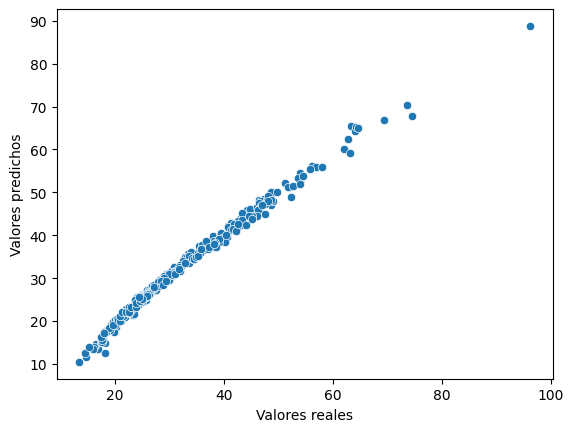

In [9]:
#Visualizar la precision de las predicciones
sns.scatterplot(data=df, x=y, y=y_pred)
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.show()

In [10]:
#Importar libreria de metricas para evaluar desempeño del modelo
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


In [11]:
#Definir los valores r2, mse y mae
r2= r2_score(y, y_pred)
mae= mean_absolute_error(y, y_pred)
mse= mean_squared_error(y, y_pred)

print(f"El valor de r2:{r2:.4f}, el valor mae:{mae:.4f} y el valor mse:{mse:.4f}")

El valor de r2:0.9887, el valor mae:0.9075 y el valor mse:1.6477


In [8]:
df.sample(5)

,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC,SEXO
273,34.90,1.49,57.0,10,0.38,15.72,F
18,19.55,1.11,57.0,5,0.51,15.87,M
121,24.30,1.25,57.0,9,0.46,15.55,F
282,62.70,1.49,95.0,11,0.64,28.24,M
291,39.15,1.51,61.0,9,0.40,17.17,F


In [11]:
x57 = model.predict([[61]])
x57

c:\Users\Ivan galeno reyes\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([30.61501098])

**Conclusion:**
Generalmente a mayor numero de variables de entrada un mayor crecimiento de r2